## MLP tự viết so với MLP của scikit-learn

## 1. Cài đặt và import

**Giải thích.**
- Nạp thư viện xử lý số (`numpy`), bảng dữ liệu (`pandas`) và vẽ đồ thị (`matplotlib`).
- Từ `scikit-learn`: `train_test_split` để chia dữ liệu, `MLPClassifier` (đặt bí danh `SklearnMLPClassifier` để không trùng tên với MLP tự viết) và các hàm độ đo (`accuracy`, `precision`, `recall`, `f1`, `classification_report`, `confusion_matrix`).
- Thêm thư mục gốc project vào `sys.path` để import được package `src`, sau đó nạp `load_prepared_mnist` từ `src/data.py`.
- `SEED = 42` là seed dùng chung cho mọi bước chia dữ liệu và khởi tạo mô hình, giúp kết quả tái lập được.

In [1]:
from IPython.display import display
import sys
import time
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier as SklearnMLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


from pathlib import Path
import json
import platform
import sklearn
import joblib
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
SEED = 42
OUTPUT = ROOT / 'results' / 'mlp'
OUTPUT.mkdir(parents=True, exist_ok=True)
def save_table(table, filename):
    table.to_csv(OUTPUT / filename, index=False, encoding='utf-8-sig')
def save_figure(filename):
    plt.gcf().savefig(OUTPUT / filename, dpi=300, bbox_inches='tight')
def json_default(value):
    if isinstance(value, np.generic): return value.item()
    raise TypeError(f'Cannot serialize {type(value)}')

## 2. Nạp data MNIST

**Giải thích.**
- `load_prepared_mnist()` trả về ảnh đã chuẩn hóa và làm phẳng: pixel đưa từ `uint8 [0, 255]` về `float32 [0, 1]`, mỗi ảnh 28×28 thành vector 784 chiều.
- Chuyển sang `np.float32` để tính toán nhanh hơn và `reshape(-1)` cho nhãn để luôn là vector 1 chiều.
- Các câu `assert` kiểm tra dữ liệu đúng định dạng: 784 đặc trưng, số ảnh khớp số nhãn.
- In kích thước, khoảng giá trị pixel và danh sách nhãn để xác nhận dữ liệu đã sẵn sàng.

In [2]:
X_train_full, y_train_raw, X_test_full, y_test_all = load_prepared_mnist()

X_all = np.asarray(X_train_full, dtype=np.float32)
y_all = np.asarray(y_train_raw).reshape(-1)
X_test_full = np.asarray(X_test_full, dtype=np.float32)
y_test_all = np.asarray(y_test_all).reshape(-1)

assert X_all.ndim == 2 and X_all.shape[1] == 784
assert X_test_full.ndim == 2 and X_test_full.shape[1] == 784
assert len(X_all) == len(y_all) and len(X_test_full) == len(y_test_all)

print("Train gốc:", X_all.shape, "| Test gốc:", X_test_full.shape)
print("Khoảng pixel:", float(X_all.min()), "->", float(X_all.max()))
print("Nhãn:", np.unique(y_all))

Train gốc: (60000, 784) | Test gốc: (10000, 784)
Khoảng pixel: 0.0 -> 1.0
Nhãn: [0 1 2 3 4 5 6 7 8 9]


## 3. Chia tập dữ liệu thành train và validation

**Giải thích.**
- Tách 10% dữ liệu train gốc thành tập validation (`test_size=0.1`) để chọn siêu tham số; `stratify=y_all` giữ tỉ lệ 10 chữ số như nhau ở cả hai tập.
- Tập test gốc được giữ nguyên, chỉ dùng để đánh giá cuối cùng nhằm tránh rò rỉ thông tin.
- Biểu đồ cột so sánh phân bố nhãn giữa train/validation/test để kiểm tra ba tập có cùng phân phối lớp.

Train: (50000, 784) | Val: (10000, 784) | Test: (10000, 784)


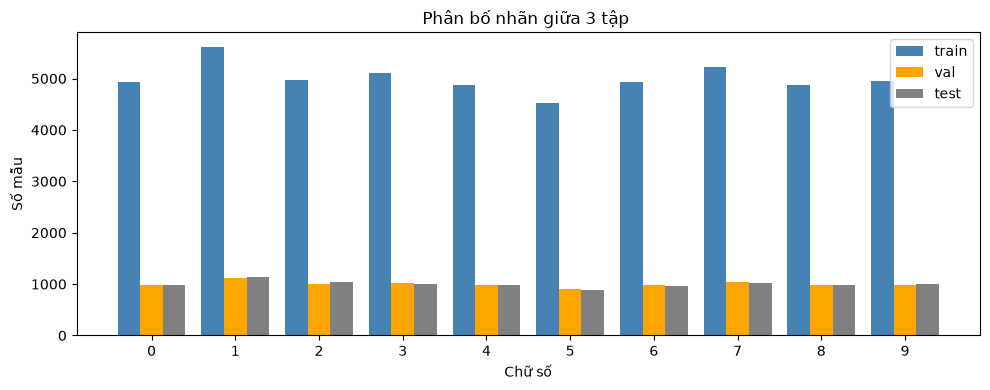

In [3]:
tr_idx, va_idx = train_test_split(
    np.arange(len(y_all)), test_size=10000, stratify=y_all, random_state=SEED
)
X_train, X_val = X_all[tr_idx], X_all[va_idx]
y_train, y_val = y_all[tr_idx], y_all[va_idx]
np.savez_compressed(OUTPUT / 'split_indices.npz', tr_idx=tr_idx, va_idx=va_idx, seed=SEED)
X_test, y_test = X_test_full, y_test_all

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

# Phân bố nhãn
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(10); w = 0.27
for i, (yv, name, col) in enumerate([
    (y_train, 'train', 'steelblue'),
    (y_val,   'val',   'orange'),
    (y_test,  'test',  'gray')
]):
    counts = np.bincount(yv, minlength=10)
    ax.bar(x + (i-1)*w, counts, w, label=name, color=col)
ax.set_xticks(x); ax.set_xlabel("Chữ số"); ax.set_ylabel("Số mẫu")
ax.set_title("Phân bố nhãn giữa 3 tập ")
ax.legend(); plt.tight_layout(); save_figure('class_distribution.png'); plt.show()

## 4. MLP đã viết bằng tay

**Giải thích.**
- Import `MLPClassifier` tự viết trong `src/models/mlp.py`: mạng truyền thẳng dùng ReLU ở các lớp ẩn, softmax + cross-entropy ở đầu ra, huấn luyện bằng SGD mini-batch có phạt L2.
- Các siêu tham số chính: `hidden_units`, `learning_rate`, `epochs`, `batch_size`, `l2`, `seed`.
- `history_` lưu loss sau mỗi epoch để vẽ loss curve; `weights_` và `biases_` là danh sách trọng số/bias của từng lớp.
- Cell dưới chỉ in ra class và cấu hình mặc định (256, 128) để xác nhận module import đúng.

In [4]:
from src.models.mlp import MLPClassifier
print("MLPClassifier được import:", MLPClassifier)
print("Kích thước các lớp ẩn mặc định:", MLPClassifier().hidden_units)

MLPClassifier được import: <class 'src.models.mlp.MLPClassifier'>
Kích thước các lớp ẩn mặc định: [256, 128]


## 5. Các hàm đánh giá

**Giải thích.**
- `evaluate`: gom các độ đo của một lần dự đoán vào dict — accuracy, precision/recall/F1 *macro* (trung bình đều cho 10 lớp) và thời gian fit/dự đoán.
- `arch_str` / `parse_arch`: chuyển kiến trúc dạng tuple `(256, 128)` thành chuỗi `"256-128"` và ngược lại, thuận tiện khi đưa vào DataFrame.
- `timed_fit`: đo thời gian huấn luyện bằng `time.perf_counter()`.
- `make_sklearn`: tạo MLP của scikit-learn với cấu hình tương đương bản tự viết (SGD, learning rate không đổi, không momentum, không early stopping) để so sánh công bằng.
- `count_parameter_manual`: đếm tổng số tham số (trọng số + bias) của MLP tự viết.

In [5]:
def evaluate(name, y_true, y_pred, fit_s, pred_s):
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'fit_seconds': fit_s,
        'predict_seconds': pred_s,
    }
def arch_str(h):
    return '-'.join(str(x) for x in h)

def parse_arch(s):
    return tuple(int(x) for x in s.split('-'))

def timed_fit(model, X, y):
    """Tính thời gian train model"""
    start = time.perf_counter()
    model.fit(X, y)
    times = time.perf_counter() - start
    return model, times

def make_sklearn(hidden, lr, epochs, batch, l2, seed):
    """Cấu hình sklearn tương đương MLP tự viết: SGD, không momentum, không early-stop."""
    return SklearnMLPClassifier(
        hidden_layer_sizes=hidden, activation='relu', solver='sgd',
        alpha=l2, batch_size=batch, learning_rate='constant',
        learning_rate_init=lr, max_iter=epochs, shuffle=True,
        momentum=0.0, nesterovs_momentum=False, tol=0.0,
        n_iter_no_change=epochs + 1, random_state=seed, verbose=False
    )

def count_parameter_manual(model):
    """Tính tổng số tham số của model (trọng số + bias).
    Tổng tham số thể hiện dung lượng bộ nhớ của mô hình.
    Quá lớn dễ bị overfitting, quá nhỏ dễ bị underfitting."""
    return int(sum(W.size for W in model.weights_)) + int(sum(b.size for b in model.biases_))

## 6. So sánh MLP tự viết với MLP của scikit-learn
Cả hai mô hình dùng: `hidden=(256,128)`, `lr=0.08`, `epochs=20`, `batch=256`, `l2=1e-4`.

**Giải thích.**
- `BASE_*` là bộ siêu tham số gốc, dùng chung cho mọi thí nghiệm: chỉ thay đổi đúng một siêu tham số đang khảo sát, các siêu tham số còn lại giữ nguyên để so sánh công bằng.
- Cả hai mô hình dùng cùng cấu hình như phần mô tả phía trên.
- Huấn luyện MLP tự viết và MLP sklearn trên `X_train`, đo thời gian fit và dự đoán trên tập validation.
- Đếm số tham số của hai mô hình: bằng nhau chứng tỏ cùng kiến trúc, nên khác biệt (nếu có) đến từ cách cài đặt thuật toán.
- `baseline_df` tổng hợp các độ đo để so sánh trực tiếp; `n_iter_` của sklearn cho biết số epoch thực tế đã chạy.

In [6]:
BASE_HIDDEN = (256, 128)
BASE_LR = 0.08
BASE_EPOCHS = 20
BASE_BATCH = 256
BASE_L2 = 1e-4

# MLP tự viết 
manual = MLPClassifier(
    hidden_units=BASE_HIDDEN, learning_rate=BASE_LR, epochs=BASE_EPOCHS,
    batch_size=BASE_BATCH, l2=BASE_L2, seed=SEED
)
manual, manual_fit_s = timed_fit(manual, X_train, y_train)
t = time.perf_counter(); manual_val = manual.predict(X_val)
manual_pred_s = time.perf_counter() - t

# MLP sklearn
sk = make_sklearn(BASE_HIDDEN, BASE_LR, BASE_EPOCHS, BASE_BATCH, BASE_L2, SEED)
sk, sk_fit_s = timed_fit(sk, X_train, y_train)
t = time.perf_counter(); sk_val = sk.predict(X_val)
sk_pred_s = time.perf_counter() - t

# Số tham số
manual_params = int(sum(w.size for w in manual.weights_) + sum(b.size for b in manual.biases_))
sk_params = int(sum(c.size for c in sk.coefs_) + sum(i.size for i in sk.intercepts_))

baseline_df = pd.DataFrame([
    evaluate('MLP tự viết', y_val, manual_val, manual_fit_s, manual_pred_s),
    evaluate('MLP sklearn', y_val, sk_val, sk_fit_s, sk_pred_s),
])
baseline_df['n_params'] = [manual_params, sk_params]

display(baseline_df.round(4))
print(f"sklearn n_iter thực tế: {sk.n_iter_} / {BASE_EPOCHS}")
print(f"Tham số — manual: {manual_params:,} | sklearn: {sk_params:,}")
save_table(baseline_df, 'baseline_validation_metrics.csv')


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds,n_params
0,MLP tự viết,0.9677,0.9680,0.9678,0.9676,27.5001,0.0219,235146
1,MLP sklearn,0.9709,0.9709,0.9706,0.9707,36.4470,0.0321,235146


sklearn n_iter thực tế: 20 / 20
Tham số — manual: 235,146 | sklearn: 235,146


## 7. Loss curve

Lưu ý: `loss_curve_` của sklearn đã cộng thêm số hạng phạt L2, nên giá trị loss của hai mô hình
có thể lệch nhau một chút do cách tính, không hoàn toàn so sánh trực tiếp được. Hình dạng đường cong (giảm theo epoch) mới là điều đáng so sánh.

**Giải thích.**
- Vẽ train loss theo epoch của bản tự viết (`manual.history_`) và bản sklearn (`sk.loss_curve_`) trên cùng một đồ thị.
- Đường cong giảm đều, không dao động mạnh cho thấy learning rate phù hợp và hai mô hình hội tụ tương tự nhau.
- Chỉ nên so sánh *hình dạng* đường cong: cách tính loss (đặc biệt là số hạng phạt L2) giữa hai thư viện có thể hơi khác nhau.

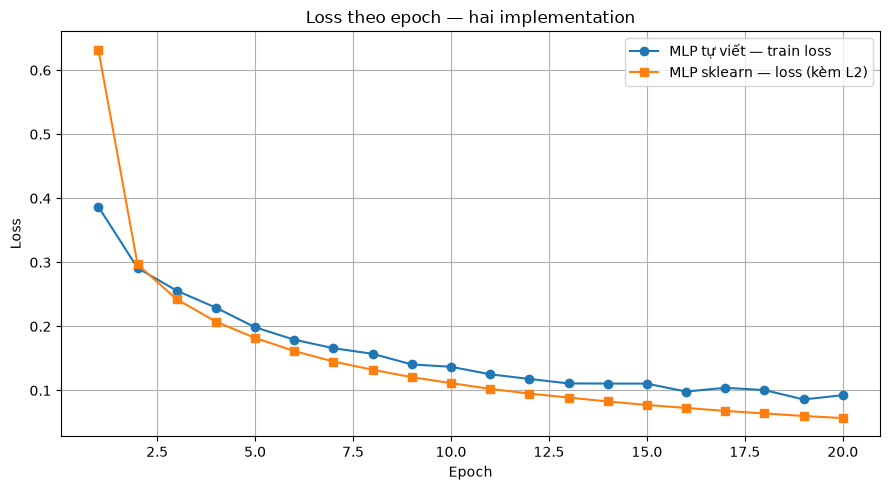

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(manual.history_) + 1), manual.history_, marker='o', label='MLP tự viết — train loss')
plt.plot(range(1, len(sk.loss_curve_) + 1), sk.loss_curve_, marker='s', label='MLP sklearn — loss (kèm L2)')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Loss theo epoch — hai implementation')
plt.legend(); plt.grid(True); plt.tight_layout(); save_figure('baseline_loss.png'); plt.show()
save_table(pd.DataFrame({'manual': pd.Series(manual.history_),
                         'sklearn': pd.Series(sk.loss_curve_)}).rename_axis('epoch_zero_based').reset_index(),
           'baseline_loss_history.csv')


## 8. Confusion matrix và hiệu năng theo từng lớp
Confusion matrix cạnh nhau cho thấy cùng mẫu nào dễ nhầm ở cả hai mô hình.

F1 theo lớp giúp thấy chữ số nào mô hình này mạnh hơn mô hình kia.

**Giải thích.**
- Vẽ confusion matrix của hai mô hình cạnh nhau để thấy chúng cùng nhầm lẫn ở những cặp chữ số nào (ví dụ 4↔9, 3↔8).
- `f1_score(..., average=None)` trả về F1 riêng cho từng chữ số; biểu đồ cột so sánh F1 theo lớp giữa hai mô hình.
- In chênh lệch F1 (`manual - sklearn`) theo từng lớp để biết mô hình nào mạnh hơn ở lớp nào.

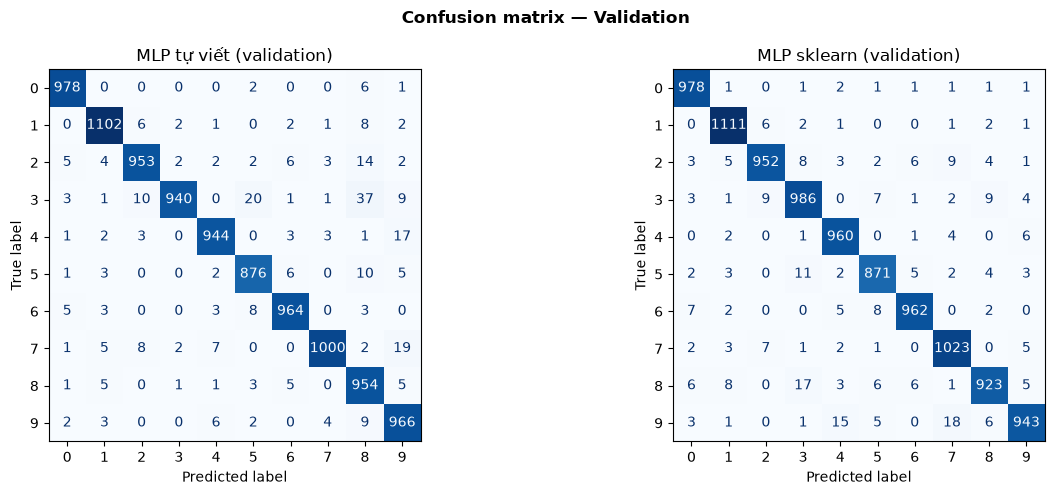

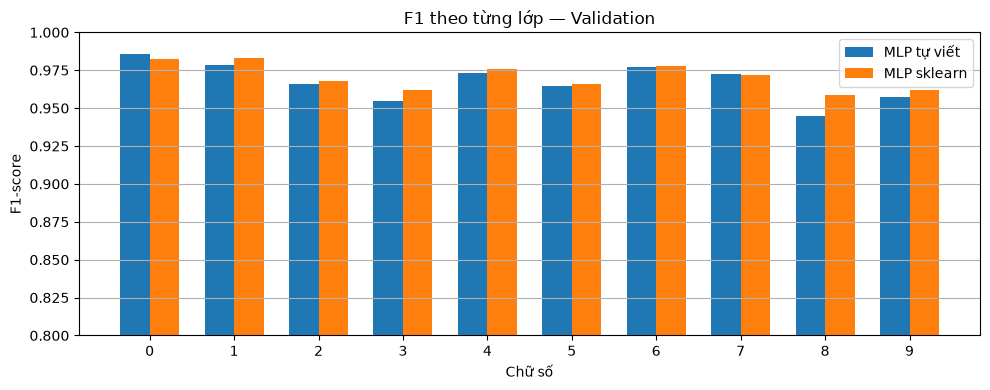

Chênh lệch F1 (manual - sklearn) theo lớp:
  Digit 0: +0.0035
  Digit 1: -0.0041
  Digit 2: -0.0019
  Digit 3: -0.0072
  Digit 4: -0.0029
  Digit 5: -0.0009
  Digit 6: -0.0005
  Digit 7: +0.0008
  Digit 8: -0.0134
  Digit 9: -0.0044


In [8]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val, manual_val, ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
axes[0].set_title('MLP tự viết (validation)')
ConfusionMatrixDisplay.from_predictions(
    y_val, sk_val, ax=axes[1], cmap='Blues', colorbar=False, values_format='d'
)
axes[1].set_title('MLP sklearn (validation)')
fig.suptitle('Confusion matrix — Validation', fontweight='bold')
plt.tight_layout(); save_figure('baseline_confusion_validation.png'); plt.show()

# F1 theo từng lớp
f1_manual = f1_score(y_val, manual_val, average=None, zero_division=0)
f1_sk = f1_score(y_val, sk_val, average=None, zero_division=0)

x = np.arange(10); w = 0.35
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, f1_manual, w, label='MLP tự viết')
ax.bar(x + w/2, f1_sk, w, label='MLP sklearn')
ax.set_xticks(x); ax.set_xlabel('Chữ số'); ax.set_ylabel('F1-score')
ax.set_ylim(0.80, 1.0); ax.set_title('F1 theo từng lớp — Validation')
ax.legend(); plt.grid(axis='y'); plt.tight_layout(); save_figure('baseline_f1_per_class.png'); plt.show()

print("Chênh lệch F1 (manual - sklearn) theo lớp:")
for d in range(10):
    print(f"  Digit {d}: {f1_manual[d] - f1_sk[d]:+.4f}")

**Giải thích.**
- So sánh từng dự đoán với nhãn thật để tạo các mảng boolean: `m_right` (manual đúng), `s_right` (sklearn đúng), `agree` (hai mô hình dự đoán giống nhau).
- Từ đó tính tỉ lệ theo 5 nhóm: hai mô hình đồng ý, cùng đúng, chỉ manual đúng, chỉ sklearn đúng và cả hai cùng sai.
- Hiển thị tối đa 8 mẫu mà hai mô hình dự đoán khác nhau (`M` = manual, `S` = sklearn) để so sánh trực quan.

Hai mô hình dự đoán giống nhau: 97.51%
Cả hai đúng:                   95.85%
Chỉ manual đúng:               0.92%
Chỉ sklearn đúng:              1.24%
Cả hai sai:                    1.99%


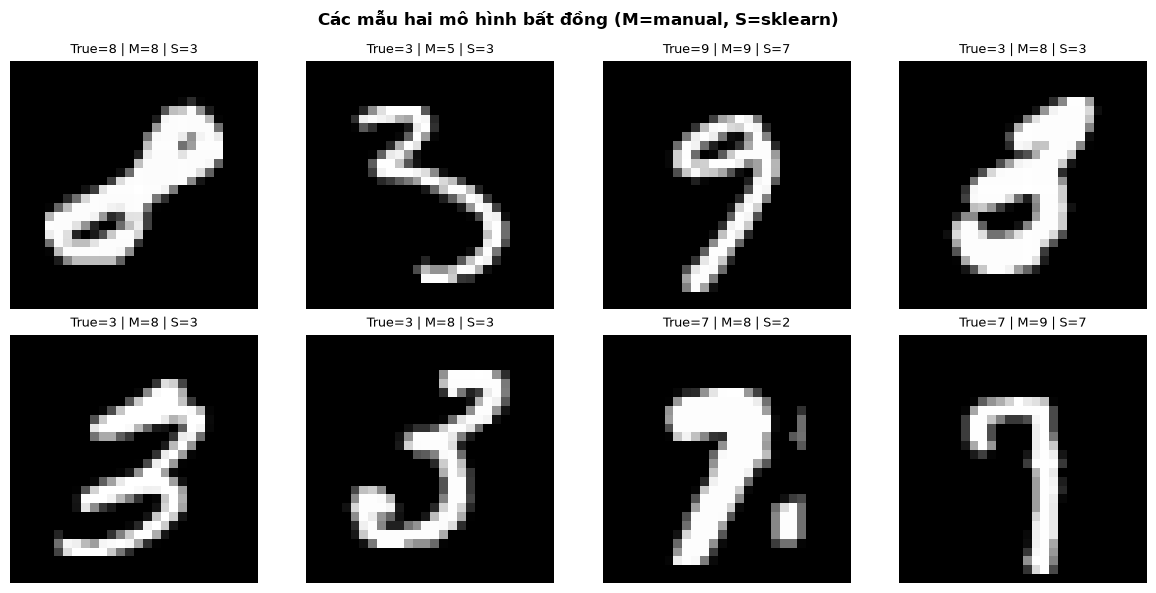

In [9]:
m_right = (manual_val == y_val) #mãng boolean
s_right = (sk_val == y_val)
agree   = (manual_val == sk_val)

print(f"Hai mô hình dự đoán giống nhau: {agree.mean()*100:.2f}%")
print(f"Cả hai đúng:                   {(m_right & s_right).mean()*100:.2f}%")
print(f"Chỉ manual đúng:               {(m_right & ~s_right).mean()*100:.2f}%")
print(f"Chỉ sklearn đúng:              {(~m_right & s_right).mean()*100:.2f}%")
print(f"Cả hai sai:                    {(~m_right & ~s_right).mean()*100:.2f}%")

# Một vài mẫu hai mô hình dự đoán khác nhau
diff_idx = np.where(manual_val != sk_val)[0][:8]
if len(diff_idx) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, idx in zip(axes.ravel(), diff_idx):
        ax.imshow(X_val[idx].reshape(28, 28), cmap='gray')
        ax.set_title(f"True={y_val[idx]} | M={manual_val[idx]} | S={sk_val[idx]}", fontsize=9)
        ax.axis('off')
    fig.suptitle('Các mẫu hai mô hình bất đồng (M=manual, S=sklearn)', fontweight='bold')
    plt.tight_layout(); save_figure('baseline_disagreements.png'); plt.show()

## 9. Thí nghiệm siêu tham số — learning rate

**Giải thích.**
- Với mỗi learning rate, huấn luyện một mô hình mới cho cả hai bản (các siêu tham số khác giữ nguyên `BASE_*`) và ghi lại F1 macro trên validation.
- Bảng pivot so sánh accuracy/F1 theo LR giữa hai implementation.
- Đồ thị dùng thang log cho trục x để các giá trị nhỏ (0.001, 0.01) không bị dồn sát nhau.
- Đánh giá trên validation, không dùng test, để tránh rò rỉ thông tin khi chọn siêu tham số.

 lr=0.001  | manual   | f1=0.8539 | 35.2s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 lr=0.001  | sklearn  | f1=0.8491 | 42.6s
 lr=0.01   | manual   | f1=0.9299 | 44.5s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 lr=0.01   | sklearn  | f1=0.9299 | 38.6s
 lr=0.05   | manual   | f1=0.9639 | 37.4s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 lr=0.05   | sklearn  | f1=0.9647 | 40.0s
 lr=0.08   | manual   | f1=0.9676 | 35.4s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 lr=0.08   | sklearn  | f1=0.9707 | 27.6s
 lr=0.1    | manual   | f1=0.9694 | 19.2s
 lr=0.1    | sklearn  | f1=0.9713 | 38.4s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


accuracy         f1_macro        
model   manual sklearn   manual sklearn
lr                                     
0.001   0.8564  0.8513   0.8539  0.8491
0.010   0.9305  0.9304   0.9299  0.9299
0.050   0.9640  0.9650   0.9639  0.9647
0.080   0.9677  0.9709   0.9676  0.9707
0.100   0.9695  0.9715   0.9694  0.9713

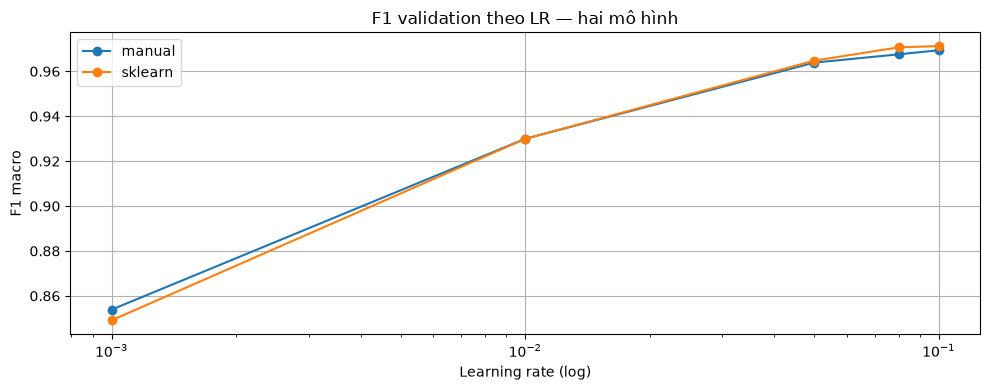

In [10]:
LR_VALUES = [0.001, 0.01, 0.05, 0.08, 0.1]
rows = []
for lr in LR_VALUES:
    for name in ['manual', 'sklearn']:
        m = (MLPClassifier(hidden_units=BASE_HIDDEN, learning_rate=lr, epochs=BASE_EPOCHS,
                           batch_size=BASE_BATCH, l2=BASE_L2, seed=SEED)
             if name == 'manual' else
             make_sklearn(BASE_HIDDEN, lr, BASE_EPOCHS, BASE_BATCH, BASE_L2, SEED))
        m, fit_s = timed_fit(m, X_train, y_train)
        t = time.perf_counter()
        pred = m.predict(X_val)
        pred_s = time.perf_counter() - t
        r = evaluate(name, y_val, pred, fit_s, pred_s)
        r['lr'] = lr
        rows.append(r)
        print(f" lr={lr:<6} | {name:8s} | f1={r['f1_macro']:.4f} | {fit_s:.1f}s")

lr_df = pd.DataFrame(rows)
display(lr_df.pivot(index='lr', columns='model', values=['accuracy', 'f1_macro']).round(4))

fig, ax = plt.subplots(figsize=(10, 4))
for name, col in [('manual', 'tab:blue'), ('sklearn', 'tab:orange')]:
    sub = lr_df[lr_df['model'] == name]
    ax.plot(sub['lr'], sub['f1_macro'], marker='o', label=name, color=col)
ax.set_xscale('log') #scale theo log để các điểm 0.001 và 0.01 không quá sát nhau
ax.set_xlabel('Learning rate (log)'); ax.set_ylabel('F1 macro')
ax.set_title('F1 validation theo LR — hai mô hình'); ax.legend(); ax.grid(True)
plt.tight_layout(); save_figure('learning_rate_search.png'); plt.show()
save_table(lr_df, 'learning_rate_search.csv')


## 10. Thí nghiệm kiến trúc mạng

**Giải thích.**
- Thử 4 kiến trúc: một lớp ẩn (128, 256), hai lớp ẩn (128-64) và ba lớp ẩn (256-128-64), giữ nguyên các siêu tham số còn lại.
- Mỗi mô hình được đo cả thời gian fit và thời gian dự đoán để thấy chi phí của mạng sâu/lớn hơn.
- So sánh F1 validation theo kiến trúc giúp chọn độ sâu/độ rộng phù hợp: mạng nhỏ dễ underfitting, mạng quá lớn dễ overfitting mà không cải thiện chất lượng.

 arch=(128,)         | manual   | f1=0.9604 | 26.8s | 0.0s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 arch=(128,)         | sklearn  | f1=0.9584 | 27.9s | 0.0s
 arch=(256,)         | manual   | f1=0.9622 | 30.4s | 0.0s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 arch=(256,)         | sklearn  | f1=0.9622 | 485.5s | 0.0s
 arch=(128, 64)      | manual   | f1=0.9653 | 204.6s | 0.0s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


 arch=(128, 64)      | sklearn  | f1=0.9660 | 254.5s | 0.0s
 arch=(256, 128, 64) | manual   | f1=0.9717 | 399.6s | 0.1s
 arch=(256, 128, 64) | sklearn  | f1=0.9693 | 557.0s | 0.0s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds,arch
0,manual,0.9606,0.960573,0.960371,0.960421,26.785793,0.017688,128
1,sklearn,0.9587,0.958552,0.958315,0.958412,27.881901,0.033670,128
2,manual,0.9624,0.962326,0.962233,0.962204,30.431084,0.029633,256
3,sklearn,0.9624,0.962381,0.962078,0.962172,485.506074,0.031803,256
4,manual,0.9655,0.965527,0.965196,0.965306,204.643743,0.022643,128-64
5,sklearn,0.9663,0.966703,0.965728,0.966041,254.483247,0.040792,128-64
6,manual,0.9718,0.971994,0.971569,0.971702,399.571943,0.051184,256-128-64
7,sklearn,0.9696,0.969496,0.969545,0.969274,557.023786,0.028888,256-128-64


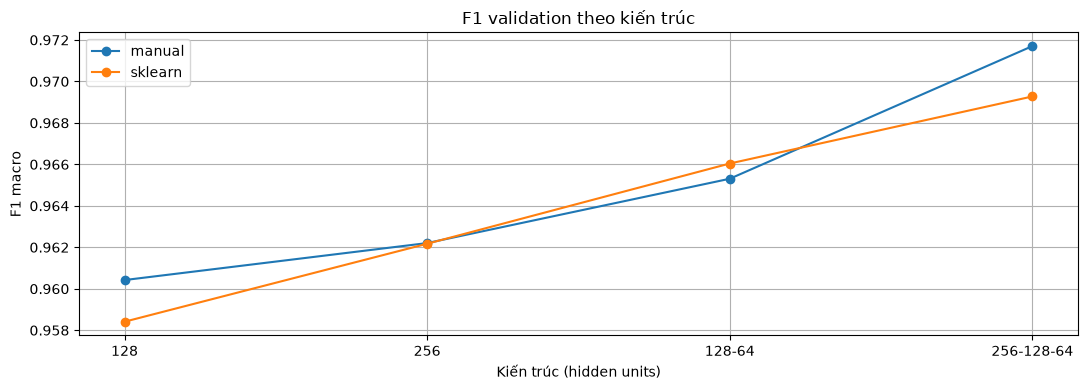

In [11]:
ARCHS = [
    (128,),
    (256,),
    (128, 64),
    (256, 128, 64)
]
rows = []
for h in ARCHS:
    for name in ['manual', 'sklearn']:
        m = (MLPClassifier(hidden_units=h, learning_rate= BASE_LR, epochs= BASE_EPOCHS
                           , batch_size= BASE_BATCH, l2 = BASE_L2, seed = SEED)
                           if name == 'manual'
                           else 
                           make_sklearn(h, BASE_LR, BASE_EPOCHS, BASE_BATCH, BASE_L2, SEED))
        m, fit_s = timed_fit(m, X_train, y_train)

        time_start_pred = time.perf_counter()
        pred = m.predict(X_val)
        pred_s = time.perf_counter() - time_start_pred

        r = evaluate(name, y_val, pred, fit_s, pred_s)
        r['arch'] = arch_str(h)
        rows.append(r)
        print(f" arch={str(h):<14} | {name:8s} | f1={r['f1_macro']:.4f} | {fit_s:.1f}s | {pred_s:.1f}s" )

arch_df = pd.DataFrame(rows)
display(arch_df)

fig, ax = plt.subplots(figsize=(11, 4))
for name, col in [('manual', 'tab:blue'), ('sklearn', 'tab:orange')]:
    sub = arch_df[arch_df['model'] == name]
    ax.plot(sub['arch'], sub['f1_macro'], marker='o', label=name, color=col)
ax.set_xlabel('Kiến trúc (hidden units)'); ax.set_ylabel('F1 macro')
ax.set_title('F1 validation theo kiến trúc'); ax.legend(); ax.grid(True)
plt.tight_layout(); save_figure('architecture_search.png'); plt.show()



save_table(arch_df, 'architecture_search.csv')


## 11. Thí nghiệm theo Epoch

**Giải thích.**
- Với mỗi số epoch, huấn luyện lại mô hình và ghi lại accuracy trên train, trên validation, F1 macro và thời gian fit.
- Đồ thị bên trái so sánh train accuracy với validation accuracy: khoảng cách giữa hai đường càng lớn thì dấu hiệu overfitting càng rõ.
- Đồ thị bên phải cho thấy F1 validation thay đổi thế nào khi tăng số epoch, để chọn số epoch hợp lý.
- Cell tiếp theo chỉ hiển thị riêng bảng kết quả của MLP tự viết cho dễ đọc.

epochs=2   | manual   | train=0.9252 | val=0.9216 | 45.0s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2) reached and the optimization hasn't converged yet.
  warnings.warn(


epochs=2   | sklearn  | train=0.9229 | val=0.9168 | 55.0s
epochs=5   | manual   | train=0.9510 | val=0.9475 | 181.8s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5) reached and the optimization hasn't converged yet.
  warnings.warn(


epochs=5   | sklearn  | train=0.9508 | val=0.9448 | 12.0s
epochs=10  | manual   | train=0.9703 | val=0.9614 | 198.3s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


... (2 outputs left out)

epochs=20  | sklearn  | train=0.9850 | val=0.9709 | 688.1s
epochs=50  | manual   | train=0.9987 | val=0.9781 | 1710.1s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


epochs=50  | sklearn  | train=0.9990 | val=0.9768 | 1561.3s


,model,epochs,train_acc,val_acc,f1_macro,fit_s
0,manual,2,0.9252,0.9216,0.9208,44.9853
1,sklearn,2,0.9229,0.9168,0.9161,55.0360
2,manual,5,0.9510,0.9475,0.9471,181.7854
3,sklearn,5,0.9508,0.9448,0.9445,12.0170
4,manual,10,0.9703,0.9614,0.9612,198.3139
5,sklearn,10,0.9673,0.9579,0.9578,322.8151
6,manual,20,0.9827,0.9677,0.9676,645.6192
7,sklearn,20,0.9850,0.9709,0.9707,688.1167
8,manual,50,0.9987,0.9781,0.9780,1710.0635
9,sklearn,50,0.9990,0.9768,0.9767,1561.3260


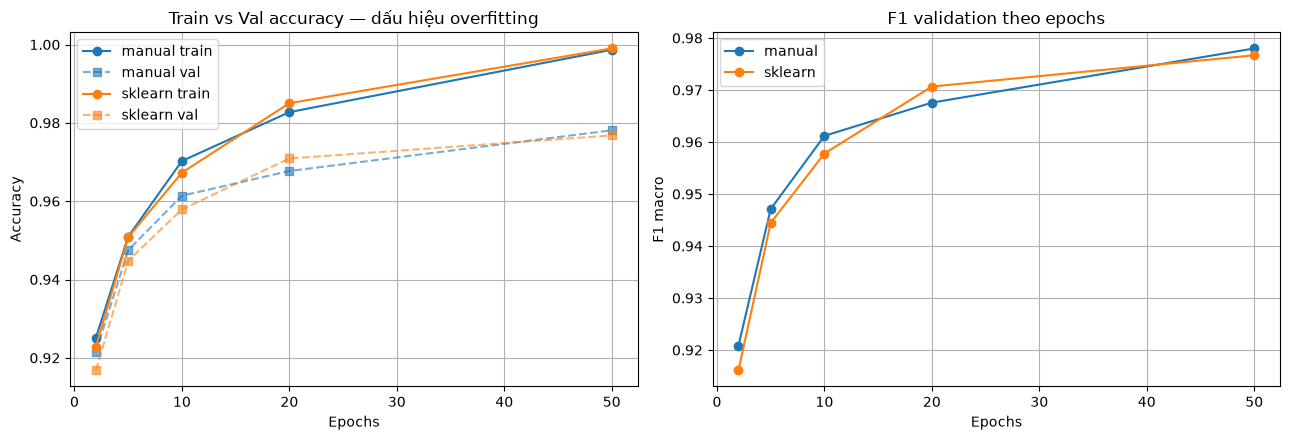

In [12]:
EPOCHS = [2, 5, 10, 20, 50]
rows = []
for ep in EPOCHS:
    for name in ['manual', 'sklearn']:
        m = (MLPClassifier(hidden_units=BASE_HIDDEN, learning_rate=BASE_LR, epochs=ep,
                           batch_size=BASE_BATCH, l2=BASE_L2, seed=SEED)
             if name == 'manual' else
             make_sklearn(BASE_HIDDEN, BASE_LR, ep, BASE_BATCH, BASE_L2, SEED))
        m, fit_s = timed_fit(m, X_train, y_train)
        val_p = m.predict(X_val)
        tr_p  = m.predict(X_train)        
        rows.append({
            'model': name, 'epochs': ep,
            'train_acc': accuracy_score(y_train, tr_p),
            'val_acc':   accuracy_score(y_val, val_p),
            'f1_macro':  f1_score(y_val, val_p, average='macro', zero_division=0),
            'fit_s': fit_s,
        })
        print(f"epochs={ep:<3} | {name:8s} | train={rows[-1]['train_acc']:.4f} "
              f"| val={rows[-1]['val_acc']:.4f} | {fit_s:.1f}s")

ep_df = pd.DataFrame(rows)
display(ep_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, col in [('manual', 'tab:blue'), ('sklearn', 'tab:orange')]:
    sub = ep_df[ep_df['model'] == name]
    axes[0].plot(sub['epochs'], sub['train_acc'], marker='o', label=f'{name} train', color=col)
    axes[0].plot(sub['epochs'], sub['val_acc'], marker='s', linestyle='--',
                 label=f'{name} val', color=col, alpha=0.6)
axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Accuracy')
axes[0].set_title('Train vs Val accuracy — dấu hiệu overfitting')
axes[0].legend(); axes[0].grid(True)

for name, col in [('manual', 'tab:blue'), ('sklearn', 'tab:orange')]:
    sub = ep_df[ep_df['model'] == name]
    axes[1].plot(sub['epochs'], sub['f1_macro'], marker='o', label=name, color=col)
axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('F1 macro')
axes[1].set_title('F1 validation theo epochs')
axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); save_figure('epochs_search.png'); plt.show()
save_table(ep_df, 'epochs_search.csv')


**Giải thích.**
- Chỉ lọc và hiển thị riêng bảng kết quả của MLP tự viết (bảng đầy đủ ở cell trên đã có cả hai mô hình).

In [13]:
display(ep_df[ep_df['model'] == "manual"])

,model,epochs,train_acc,val_acc,f1_macro,fit_s
0,manual,2,0.92516,0.9216,0.920836,44.985277
2,manual,5,0.95096,0.9475,0.947109,181.785413
4,manual,10,0.97026,0.9614,0.961187,198.313915
6,manual,20,0.98274,0.9677,0.967573,645.619230
8,manual,50,0.99866,0.9781,0.977994,1710.063512


overfitting xảy ra khi train_acc -> 1 và hiệu train_acc - val_acc ngày càng lớn

## 12. Test với L2

**Giải thích.**
- Khảo sát hệ số phạt L2 (`l2` với bản tự viết, `alpha` với sklearn) từ 0 đến `1e-2`, giữ các siêu tham số khác ở giá trị baseline.
- L2 phạt trọng số lớn để hạn chế overfitting; quá nhỏ thì không có tác dụng, quá lớn thì mô hình bị underfitting.
- Bảng pivot và đồ thị F1 theo L2 giúp chọn giá trị cân bằng giữa hai hiện tượng này.

l2=0.0      | manual   | f1=0.9682 | 714.8s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


l2=0.0      | sklearn  | f1=0.9706 | 653.6s
l2=1e-05    | manual   | f1=0.9684 | 865.7s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


l2=1e-05    | sklearn  | f1=0.9706 | 940.2s
l2=0.0001   | manual   | f1=0.9676 | 971.7s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


l2=0.0001   | sklearn  | f1=0.9707 | 34.0s
l2=0.001    | manual   | f1=0.9666 | 37.0s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


l2=0.001    | sklearn  | f1=0.9703 | 159.6s
l2=0.01     | manual   | f1=0.9380 | 32.4s
l2=0.01     | sklearn  | f1=0.9707 | 48.7s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


accuracy         f1_macro        
model     manual sklearn   manual sklearn
l2                                       
0.00000   0.9683  0.9708   0.9682  0.9706
0.00001   0.9685  0.9708   0.9684  0.9706
0.00010   0.9677  0.9709   0.9676  0.9707
0.00100   0.9667  0.9705   0.9666  0.9703
0.01000   0.9383  0.9709   0.9380  0.9707

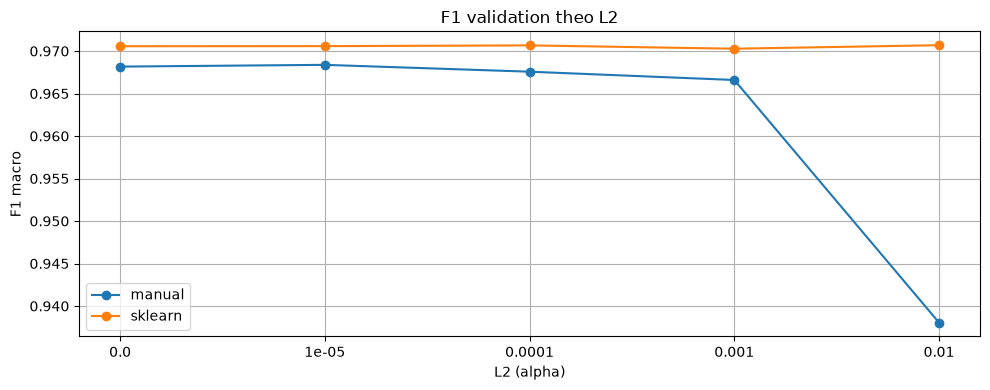

In [14]:
L2_VALUES = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]
rows = []
for l2 in L2_VALUES:
    for name in ['manual', 'sklearn']:
        m = (MLPClassifier(hidden_units=BASE_HIDDEN, learning_rate=BASE_LR, epochs=BASE_EPOCHS,
                           batch_size=BASE_BATCH, l2=l2, seed=SEED)
             if name == 'manual' else
             make_sklearn(BASE_HIDDEN, BASE_LR, BASE_EPOCHS, BASE_BATCH, l2, SEED))
        m, fit_s = timed_fit(m, X_train, y_train)
        t = time.perf_counter()
        pred = m.predict(X_val)
        pred_s = time.perf_counter() - t
        r = evaluate(name, y_val, pred, fit_s, pred_s)
        r['l2'] = l2
        rows.append(r)
        print(f"l2={l2:<8} | {name:8s} | f1={r['f1_macro']:.4f} | {fit_s:.1f}s")

l2_df = pd.DataFrame(rows)
display(l2_df.pivot(index='l2', columns='model', values=['accuracy', 'f1_macro']).round(4))

fig, ax = plt.subplots(figsize=(10, 4))
for name, col in [('manual', 'tab:blue'), ('sklearn', 'tab:orange')]:
    sub = l2_df[l2_df['model'] == name]
    ax.plot(sub['l2'].astype(str), sub['f1_macro'], marker='o', label=name, color=col)
ax.set_xlabel('L2 (alpha)'); ax.set_ylabel('F1 macro')
ax.set_title('F1 validation theo L2'); ax.legend(); ax.grid(True)
plt.tight_layout(); save_figure('l2_search.png'); plt.show()
save_table(l2_df, 'l2_search.csv')


## 13. Test với Batch Size

**Giải thích.**
- Khảo sát batch size từ 32 đến 512: batch nhỏ cập nhật nhiều lần hơn trong mỗi epoch (gradient nhiễu hơn), batch lớn cho gradient ổn định hơn nhưng ít bước cập nhật.
- Bảng pivot so sánh F1 và thời gian fit giữa hai mô hình theo batch size.
- Đồ thị bên trái so sánh chất lượng, bên phải so sánh thời gian huấn luyện — batch nhỏ thường chậm hơn vì chạy nhiều bước cập nhật hơn.

batch=32   | manual   | f1=0.9810 | 698.3s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


batch=32   | sklearn  | f1=0.9808 | 725.3s
batch=64   | manual   | f1=0.9789 | 398.8s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


batch=64   | sklearn  | f1=0.9783 | 336.3s
batch=128  | manual   | f1=0.9753 | 280.2s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


batch=128  | sklearn  | f1=0.9770 | 255.6s
batch=256  | manual   | f1=0.9676 | 37.1s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


batch=256  | sklearn  | f1=0.9707 | 33.1s
batch=512  | manual   | f1=0.9616 | 18.3s
batch=512  | sklearn  | f1=0.9618 | 14.1s


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


f1_macro         fit_seconds          
model   manual sklearn      manual   sklearn
batch                                       
32      0.9810  0.9808    698.2526  725.2574
64      0.9789  0.9783    398.7967  336.2866
128     0.9753  0.9770    280.2065  255.6053
256     0.9676  0.9707     37.0947   33.0710
512     0.9616  0.9618     18.2593   14.0709

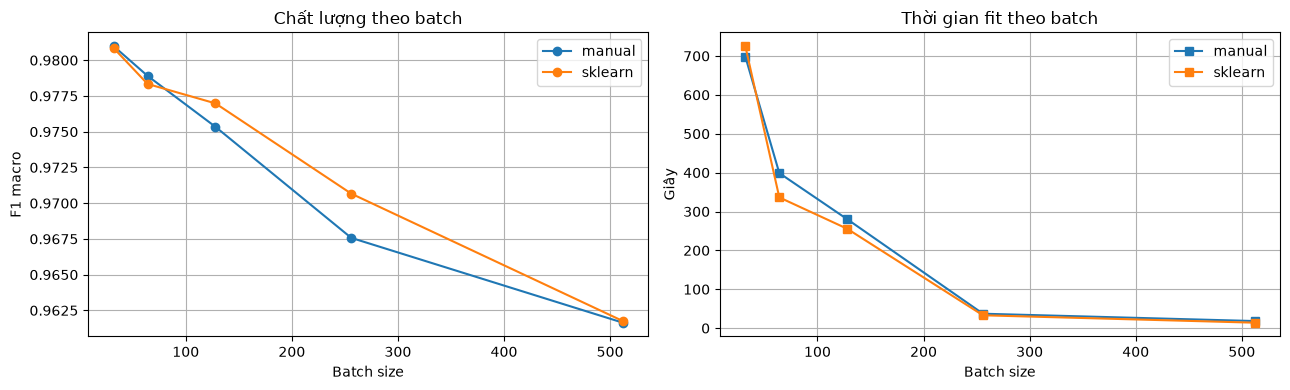

In [15]:
BATCH_VALUES = [32, 64, 128, 256, 512]
rows = []
for b in BATCH_VALUES:
    for name in ['manual', 'sklearn']:
        m = (MLPClassifier(hidden_units=BASE_HIDDEN, learning_rate=BASE_LR, epochs=BASE_EPOCHS,
                           batch_size=b, l2=BASE_L2, seed=SEED)
             if name == 'manual' else
             make_sklearn(BASE_HIDDEN, BASE_LR, BASE_EPOCHS, b, BASE_L2, SEED))
        m, fit_s = timed_fit(m, X_train, y_train)
        t = time.perf_counter()
        pred = m.predict(X_val)
        pred_s = time.perf_counter() - t
        r = evaluate(name, y_val, pred, fit_s, pred_s)
        r['batch'] = b
        rows.append(r)
        print(f"batch={b:<4} | {name:8s} | f1={r['f1_macro']:.4f} | {fit_s:.1f}s")

batch_df = pd.DataFrame(rows)
display(batch_df.pivot(index='batch', columns='model',
                        values=['f1_macro', 'fit_seconds']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, col in [('manual', 'tab:blue'), ('sklearn', 'tab:orange')]:
    sub = batch_df[batch_df['model'] == name]
    axes[0].plot(sub['batch'], sub['f1_macro'], marker='o', label=name, color=col)
    axes[1].plot(sub['batch'], sub['fit_seconds'], marker='s', label=name, color=col)
axes[0].set_xlabel('Batch size'); axes[0].set_ylabel('F1 macro')
axes[0].set_title('Chất lượng theo batch'); axes[0].legend(); axes[0].grid(True)
axes[1].set_xlabel('Batch size'); axes[1].set_ylabel('Giây')
axes[1].set_title('Thời gian fit theo batch'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); save_figure('batch_size_search.png'); plt.show()
save_table(batch_df, 'batch_size_search.csv')


## 14. Đánh giá các lỗi sai

**Giải thích.**
- Tính confusion matrix của MLP tự viết trên validation, đưa đường chéo (dự đoán đúng) về 0 để chỉ còn các ô nhầm lẫn.
- Sắp xếp giảm dần và in các cặp `thật -> dự đoán` bị nhầm nhiều nhất.
- Hiển thị 8 ảnh bị dự đoán sai kèm nhãn thật và nhãn dự đoán để phân tích trực quan các lỗi điển hình.

Các cặp bị nhầm lẫn nhiều nhất theo MLP tự viết
3 -> 8 : 37 lần
3 -> 5 : 20 lần
7 -> 9 : 19 lần
4 -> 9 : 17 lần
2 -> 8 : 14 lần
5 -> 8 : 10 lần
3 -> 2 : 10 lần
9 -> 8 : 9 lần
3 -> 9 : 9 lần
7 -> 2 : 8 lần
6 -> 5 : 8 lần
1 -> 8 : 8 lần
7 -> 4 : 7 lần
9 -> 4 : 6 lần
5 -> 6 : 6 lần
2 -> 6 : 6 lần
1 -> 2 : 6 lần
0 -> 8 : 6 lần
8 -> 9 : 5 lần
8 -> 6 : 5 lần
8 -> 1 : 5 lần
7 -> 1 : 5 lần
6 -> 0 : 5 lần
5 -> 9 : 5 lần
2 -> 0 : 5 lần
9 -> 7 : 4 lần
2 -> 1 : 4 lần
9 -> 1 : 3 lần
8 -> 5 : 3 lần
6 -> 8 : 3 lần
6 -> 4 : 3 lần
6 -> 1 : 3 lần
5 -> 1 : 3 lần
4 -> 7 : 3 lần
4 -> 6 : 3 lần
4 -> 2 : 3 lần
3 -> 0 : 3 lần
2 -> 7 : 3 lần
9 -> 5 : 2 lần
9 -> 0 : 2 lần
7 -> 8 : 2 lần
7 -> 3 : 2 lần
5 -> 4 : 2 lần
4 -> 1 : 2 lần
2 -> 9 : 2 lần
2 -> 5 : 2 lần
2 -> 4 : 2 lần
2 -> 3 : 2 lần
1 -> 9 : 2 lần
1 -> 6 : 2 lần
1 -> 3 : 2 lần
0 -> 5 : 2 lần
8 -> 4 : 1 lần
8 -> 3 : 1 lần
8 -> 0 : 1 lần
7 -> 0 : 1 lần
5 -> 0 : 1 lần
4 -> 8 : 1 lần
4 -> 0 : 1 lần
3 -> 7 : 1 lần
3 -> 6 : 1 lần
3 -> 1 : 1 lần
1 -> 7 : 1 lần


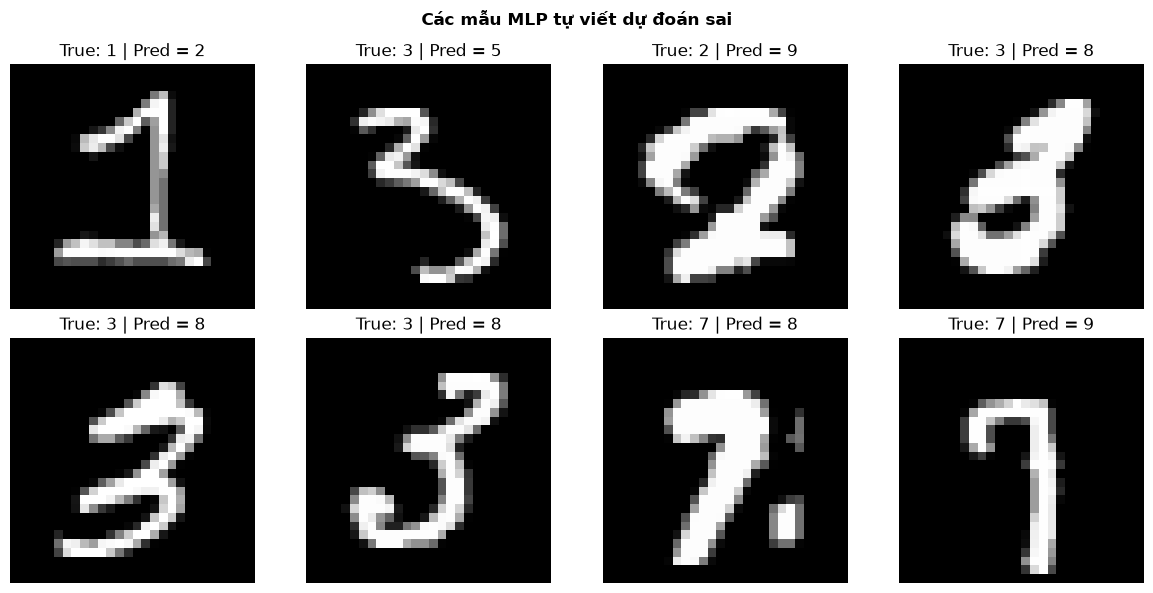

In [16]:
cm = confusion_matrix(y_val, manual_val)
np.fill_diagonal(cm, 0) #biến các giá trị trên đường chéo chính thành 0
pairs = [(cm[i,j], i, j) for i in range(10) for j in range(10) if i!= j and cm[i,j] > 0]
pairs.sort(reverse= True)

print("Các cặp bị nhầm lẫn nhiều nhất theo MLP tự viết")
for cnt, i, j in pairs:
    print(f"{i} -> {j} : {cnt} lần")

#Một vài ảnh bị dự đoán sai
wrong_idx = np.where(manual_val != y_val)[0][:8]
if (len(wrong_idx) > 0):
    fig, axes = plt.subplots(2,4, figsize = (12,6))
    for ax, idx in zip(axes.ravel(), wrong_idx):
        ax.imshow(X_val[idx].reshape(28,28), cmap = "gray")
        ax.set_title(f"True: {y_val[idx]} | Pred = {manual_val[idx]}")
        ax.axis('off')

    fig.suptitle('Các mẫu MLP tự viết dự đoán sai', fontweight='bold')
    plt.tight_layout(); save_figure('baseline_errors.png'); plt.show()


save_table(pd.DataFrame(pairs, columns=['count', 'true_label', 'predicted_label']), 'baseline_error_pairs.csv')


## 15. Chọn cấu hình tốt nhất bằng validation và đánh giá trên test

**Giải thích.**
- `best_param` chọn giá trị của một siêu tham số có F1 macro cao nhất trên validation, riêng cho từng mô hình.
- Tổng hợp cấu hình tốt nhất theo từng siêu tham số đã khảo sát (kiến trúc, learning rate, epochs, batch size, L2) thành dict `best_manual` / `best_sk`.
- Huấn luyện lại hai mô hình cuối cùng với cấu hình đó, rồi đánh giá trên cả validation và test (dữ liệu test giờ mới được dùng).
- `final` so sánh accuracy/F1 trên validation và accuracy/precision/recall/F1 trên test; cuối cùng in `classification_report` chi tiết theo từng chữ số trên test.

In [17]:
def best_param(df, param, name):
    sub = df[df['model'] == name]
    return sub.loc[sub['f1_macro'].idxmax(), param]

# Lấy siêu tham số tốt nhất cho từng mô hình
best_manual = {
    'hidden_units': parse_arch(best_param(arch_df, 'arch', 'manual')),
    'learning_rate':     best_param(lr_df, 'lr', 'manual'),
    'epochs': best_param(ep_df, 'epochs', 'manual'),
    'batch_size':  best_param(batch_df, 'batch', 'manual'),
    'l2':     best_param(l2_df, 'l2', 'manual'),
}
best_sk = {
    'hidden': parse_arch(best_param(arch_df, 'arch', 'sklearn')),
    'lr':     best_param(lr_df, 'lr', 'sklearn'),
    'epochs': best_param(ep_df, 'epochs', 'sklearn'),
    'batch':  best_param(batch_df, 'batch', 'sklearn'),
    'l2':     best_param(l2_df, 'l2', 'sklearn'),
}
print("Cấu hình tốt nhất — MLP tự viết:", best_manual)
print("Cấu hình tốt nhất — MLP sklearn :", best_sk)

# Huấn luyện lại trên toàn bộ X_train
m_final = MLPClassifier(seed=SEED, **best_manual)
m_final, m_fit = timed_fit(m_final, X_train, y_train)

s_final = make_sklearn(seed=SEED, **best_sk)
s_final, s_fit = timed_fit(s_final, X_train, y_train)

# Dự đoán val + test 
m_val_pred  = m_final.predict(X_val);  m_test_pred = m_final.predict(X_test)
s_val_pred  = s_final.predict(X_val);  s_test_pred = s_final.predict(X_test)

final = pd.DataFrame([
    {'model': 'MLP tự viết',
     'val_acc':  accuracy_score(y_val, m_val_pred),
     'val_f1':   f1_score(y_val, m_val_pred, average='macro', zero_division=0),
     'test_acc': accuracy_score(y_test, m_test_pred),
     'test_precision': precision_score(y_test, m_test_pred, average='macro', zero_division=0),
     'test_recall':    recall_score(y_test, m_test_pred, average='macro', zero_division=0),
     'test_f1':  f1_score(y_test, m_test_pred, average='macro', zero_division=0),
     'fit_s':    m_fit},
    {'model': 'MLP sklearn',
     'val_acc':  accuracy_score(y_val, s_val_pred),
     'val_f1':   f1_score(y_val, s_val_pred, average='macro', zero_division=0),
     'test_acc': accuracy_score(y_test, s_test_pred),
     'test_precision': precision_score(y_test, s_test_pred, average='macro', zero_division=0),
     'test_recall':    recall_score(y_test, s_test_pred, average='macro', zero_division=0),
     'test_f1':  f1_score(y_test, s_test_pred, average='macro', zero_division=0),
     'fit_s':    s_fit},
])
display(final.round(4))

print("\nClassification report — MLP tự viết trên TEST:")
print(classification_report(y_test, m_test_pred, digits=4, zero_division=0))
print("\nClassification report — MLP sklearn trên TEST:")
print(classification_report(y_test, s_test_pred, digits=4, zero_division=0))
save_table(final, 'final_comparison.csv')


Cấu hình tốt nhất — MLP tự viết: {'hidden_units': (256, 128, 64), 'learning_rate': np.float64(0.1), 'epochs': np.int64(50), 'batch_size': np.int64(32), 'l2': np.float64(1e-05)}
Cấu hình tốt nhất — MLP sklearn : {'hidden': (256, 128, 64), 'lr': np.float64(0.1), 'epochs': np.int64(50), 'batch': np.int64(32), 'l2': np.float64(0.01)}


d:\Nhận dạng mẫu\mnist1\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,val_acc,val_f1,test_acc,test_precision,test_recall,test_f1,fit_s
0,MLP tự viết,0.9830,0.9829,0.9819,0.9819,0.9817,0.9818,1980.5325
1,MLP sklearn,0.9834,0.9833,0.9841,0.9841,0.9840,0.9840,1960.3895



Classification report — MLP tự viết trên TEST:
              precision    recall  f1-score   support

           0     0.9838    0.9918    0.9878       980
           1     0.9921    0.9938    0.9930      1135
           2     0.9798    0.9855    0.9826      1032
           3     0.9811    0.9752    0.9782      1010
           4     0.9836    0.9766    0.9801       982
           5     0.9864    0.9765    0.9814       892
           6     0.9854    0.9833    0.9843       958
           7     0.9786    0.9776    0.9781      1028
           8     0.9755    0.9805    0.9780       974
           9     0.9724    0.9762    0.9743      1009

    accuracy                         0.9819     10000
   macro avg     0.9819    0.9817    0.9818     10000
weighted avg     0.9819    0.9819    0.9819     10000


Classification report — MLP sklearn trên TEST:
              precision    recall  f1-score   support

           0     0.9808    0.9929    0.9868       980
           1     0.9912    0.9930   

## 16. Lưu mô hình và kết quả cuối vào `results/mlp/`
Các tệp cùng tên được ghi đè khi chạy lại. Cấu hình cuối ghép từ các khảo sát riêng lẻ, chưa phải kết quả tìm kiếm đồng thời toàn bộ siêu tham số.


In [18]:
config = dict(seed=SEED, validation_fraction=0.1, stratified=True,
              n_train=len(y_train), n_validation=len(y_val), n_test=len(y_test),
              input_dtype=str(X_train.dtype),
              baseline=dict(hidden_units=BASE_HIDDEN, learning_rate=BASE_LR, epochs=BASE_EPOCHS,
                            batch_size=BASE_BATCH, l2=BASE_L2),
              grids=dict(learning_rate=LR_VALUES, architecture=ARCHS, epochs=EPOCHS,
                         l2=L2_VALUES, batch_size=BATCH_VALUES),
              final_manual=best_manual, final_sklearn=best_sk,
              selection='Combine best values from separate validation sweeps')
(OUTPUT / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2,
                                             default=json_default), encoding='utf-8')
np.savez_compressed(OUTPUT / 'baseline_predictions_validation.npz', y_true=y_val,
                    manual=manual_val, sklearn=sk_val, original_train_index=va_idx)
parameters = {f'W{i}': W for i, W in enumerate(m_final.weights_)}
parameters.update({f'b{i}': b for i, b in enumerate(m_final.biases_)})
np.savez_compressed(OUTPUT / 'manual_parameters.npz', **parameters)
joblib.dump(m_final, OUTPUT / 'manual_model.joblib')
joblib.dump(s_final, OUTPUT / 'sklearn_model.joblib')
for name, history in [('manual', m_final.history_), ('sklearn', s_final.loss_curve_)]:
    save_table(pd.DataFrame(dict(epoch=np.arange(1, len(history) + 1), loss=history)),
               f'final_loss_{name}.csv')
metric_rows = []
for name, model, fit_s in [('manual', m_final, m_fit), ('sklearn', s_final, s_fit)]:
    for split, X, y in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
        t = time.perf_counter()
        pred = model.predict(X)
        row = evaluate(name, y, pred, fit_s, time.perf_counter() - t)
        row['split'] = split
        metric_rows.append(row)
        labels = np.arange(10)
        matrix = confusion_matrix(y, pred, labels=labels)
        pd.DataFrame(matrix, index=labels, columns=labels).to_csv(
            OUTPUT / f'confusion_{name}_{split}.csv', index_label='true_label')
        report = classification_report(y, pred, labels=labels, output_dict=True, zero_division=0)
        pd.DataFrame(report).T.to_csv(OUTPUT / f'classification_report_{name}_{split}.csv')
        np.savez_compressed(OUTPUT / f'predictions_{name}_{split}.npz', y_true=y, y_pred=pred)
        fig, ax = plt.subplots(figsize=(7, 6))
        ConfusionMatrixDisplay(matrix, display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'MLP {name} — {split}')
        fig.tight_layout()
        save_figure(f'confusion_{name}_{split}.png')
        plt.close(fig)
save_table(pd.DataFrame(metric_rows), 'metrics_all_splits.csv')
print('Đã lưu kết quả vào:', OUTPUT)
for path in sorted(OUTPUT.iterdir()):
    print(' -', path.name)


Đã lưu kết quả vào: d:\Nhận dạng mẫu\mnist1\results\mlp
 - architecture_search.csv
 - architecture_search.png
 - baseline_confusion_validation.png
 - baseline_disagreements.png
 - baseline_error_pairs.csv
 - baseline_errors.png
 - baseline_f1_per_class.png
 - baseline_loss.png
 - baseline_loss_history.csv
 - baseline_predictions_validation.npz
 - baseline_validation_metrics.csv
 - batch_size_search.csv
 - batch_size_search.png
 - class_distribution.png
 - classification_report_manual_test.csv
 - classification_report_manual_train.csv
 - classification_report_manual_validation.csv
 - classification_report_sklearn_test.csv
 - classification_report_sklearn_train.csv
 - classification_report_sklearn_validation.csv
 - config.json
 - confusion_manual_test.csv
 - confusion_manual_test.png
 - confusion_manual_train.csv
 - confusion_manual_train.png
 - confusion_manual_validation.csv
 - confusion_manual_validation.png
 - confusion_sklearn_test.csv
 - confusion_sklearn_test.png
 - confusion_skle